In [1]:
print("Hello")

Hello


In [2]:
from datasets import load_dataset

In [3]:
from datasets import load_dataset

dataset = load_dataset(
    "McAuley-Lab/Amazon-Reviews-2023",
    "raw_review_All_Beauty",
    trust_remote_code=True
)

print(dataset)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'McAuley-Lab/Amazon-Reviews-2023' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


RuntimeError: Dataset scripts are no longer supported, but found Amazon-Reviews-2023.py

In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/events.csv")

print(df.head())

       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN


In [2]:
print(df.shape)

(2756101, 5)


In [3]:
print(df.columns)

Index(['timestamp', 'visitorid', 'event', 'itemid', 'transactionid'], dtype='str')


In [4]:
print("Number of users:", df["visitorid"].nunique())

Number of users: 1407580


In [5]:
print("Number of products:", df["itemid"].nunique())

Number of products: 235061


In [6]:
print(df.head(10))

       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN
5  1433224086234     972639  view   22556            NaN
6  1433221923240     810725  view  443030            NaN
7  1433223291897     794181  view  439202            NaN
8  1433220899221     824915  view  428805            NaN
9  1433221204592     339335  view   82389            NaN


In [7]:
print(df["event"].value_counts())

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


In [9]:
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

In [10]:
print(df["datetime"].min())
print(df["datetime"].max())

2015-05-03 03:00:04.384000
2015-09-18 02:59:47.788000


## 2. Data Quality Check

In [11]:
print(df.isnull().sum())

timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
datetime               0
dtype: int64


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 460


In [13]:
print(df.dtypes)

timestamp                 int64
visitorid                 int64
event                       str
itemid                    int64
transactionid           float64
datetime         datetime64[ms]
dtype: object


In [14]:
print(df["event"].unique())

<ArrowStringArray>
['view', 'addtocart', 'transaction']
Length: 3, dtype: str


In [15]:
print("Invalid visitor IDs:", (df["visitorid"] < 0).sum())
print("Invalid item IDs:", (df["itemid"] < 0).sum())

Invalid visitor IDs: 0
Invalid item IDs: 0


In [16]:
print("Unique transactions:", df["transactionid"].nunique())

Unique transactions: 17672


In [17]:
print("Before removing duplicates:", len(df))

Before removing duplicates: 2756101


In [18]:
df = df.drop_duplicates()

In [19]:
print("After removing duplicates:", len(df))

After removing duplicates: 2755641


In [22]:
import os

os.makedirs("../data/processed", exist_ok=True)

print("processed folder is ready")


processed folder is ready


In [23]:
df.to_csv("../data/processed/events_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [24]:
import os

print(os.path.exists("../data/processed/events_cleaned.csv"))

True


## 3. Exploratory Data Analysis

In [25]:
print(df["event"].value_counts())

event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64


In [ ]:
## 3. Exploratory Data Analysis
### 3.1 Event Distribution

In [26]:
event_counts = df["event"].value_counts()

print(event_counts)

event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64


In [27]:
event_percent = df["event"].value_counts(normalize=True) * 100

print(event_percent.round(2))

event
view           96.68
addtocart       2.50
transaction     0.81
Name: proportion, dtype: float64


Matplotlib is building the font cache; this may take a moment.


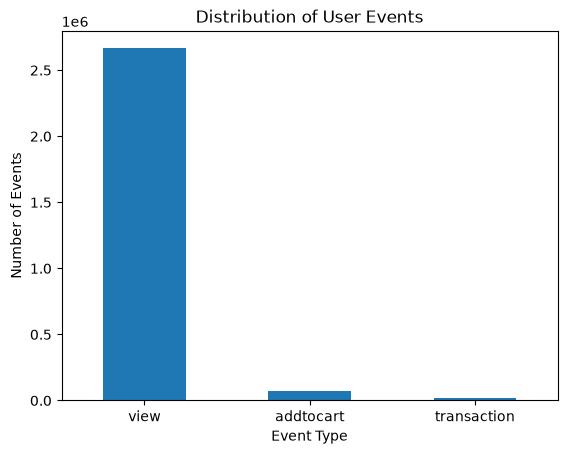

In [28]:
import matplotlib.pyplot as plt

df["event"].value_counts().plot(kind="bar")

plt.title("Distribution of User Events")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.xticks(rotation=0)
plt.show()

### 3.2 User Activity

In [29]:
user_activity = df["visitorid"].value_counts()

print(user_activity.head(10))

visitorid
1150086    7757
530559     4328
152963     3024
895999     2474
163561     2410
371606     2345
286616     2252
684514     2246
892013     2024
861299     1991
Name: count, dtype: int64


In [30]:
print("Average interactions per user:", user_activity.mean())
print("Median interactions per user:", user_activity.median())
print("Maximum interactions by one user:", user_activity.max())

Average interactions per user: 1.9577153696415124
Median interactions per user: 1.0
Maximum interactions by one user: 7757


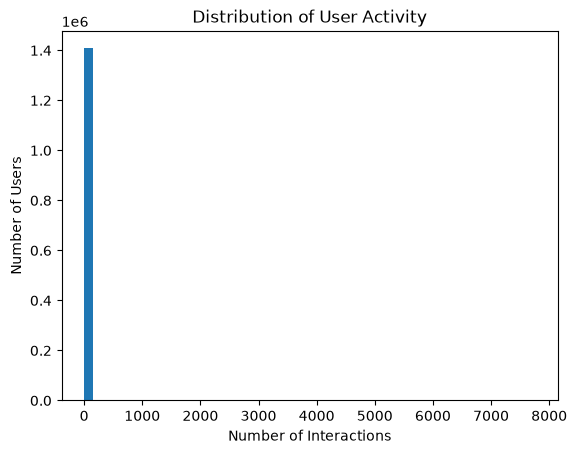

In [32]:
user_activity.plot(kind="hist", bins=50)

plt.title("Distribution of User Activity")
plt.xlabel("Number of Interactions")
plt.ylabel("Number of Users")
plt.show()

### 3.3 Product Popularity

In [33]:
product_activity = df["itemid"].value_counts()

print(product_activity.head(10))

itemid
187946    3412
461686    2975
5411      2334
370653    1854
219512    1800
257040    1647
298009    1642
96924     1633
309778    1628
384302    1608
Name: count, dtype: int64


In [34]:
print("Average interactions per product:", product_activity.mean())
print("Median interactions per product:", product_activity.median())
print("Maximum interactions for one product:", product_activity.max())

Average interactions per product: 11.723088900328
Median interactions per product: 3.0
Maximum interactions for one product: 3412


In [35]:
top_products = product_activity.head(10)

print(top_products)

itemid
187946    3412
461686    2975
5411      2334
370653    1854
219512    1800
257040    1647
298009    1642
96924     1633
309778    1628
384302    1608
Name: count, dtype: int64


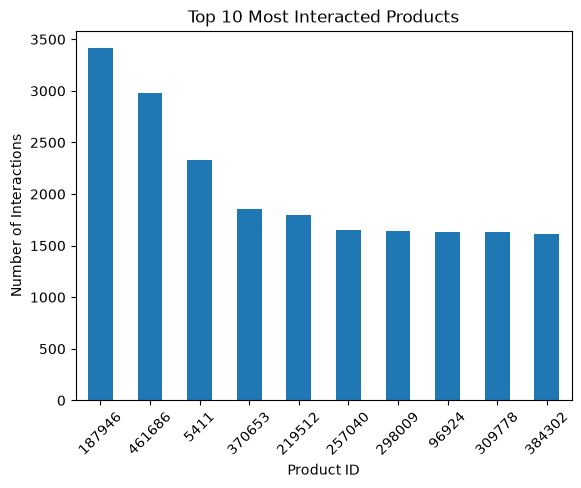

In [36]:
top_products.plot(kind="bar")

plt.title("Top 10 Most Interacted Products")
plt.xlabel("Product ID")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=45)
plt.show()

### 3.4 Interaction Activity Over Time

In [37]:
daily_activity = df.groupby(
    df["datetime"].dt.date
).size()

print(daily_activity.head())

datetime
2015-05-03    13682
2015-05-04    19413
2015-05-05    23011
2015-05-06    23920
2015-05-07    23157
dtype: int64


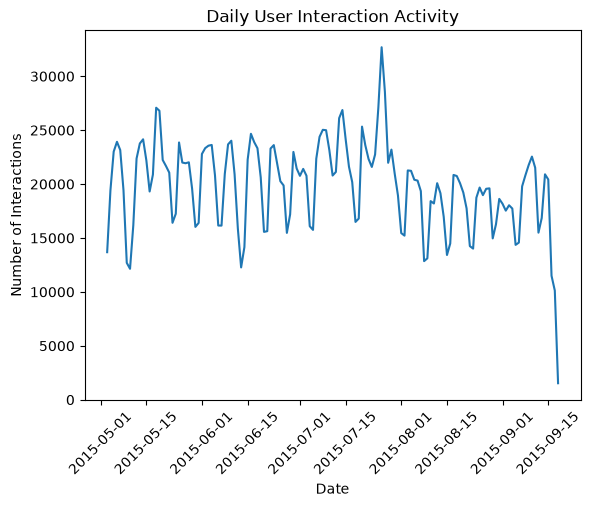

In [38]:
daily_activity.plot()

plt.title("Daily User Interaction Activity")
plt.xlabel("Date")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=45)
plt.show()

In [39]:
daily_events = pd.crosstab(
    df["datetime"].dt.date,
    df["event"]
)

print(daily_events.head())

event       addtocart  transaction   view
datetime                                 
2015-05-03        296           83  13303
2015-05-04        578          154  18681
2015-05-05        561          225  22225
2015-05-06        647          258  23015
2015-05-07        572          217  22368


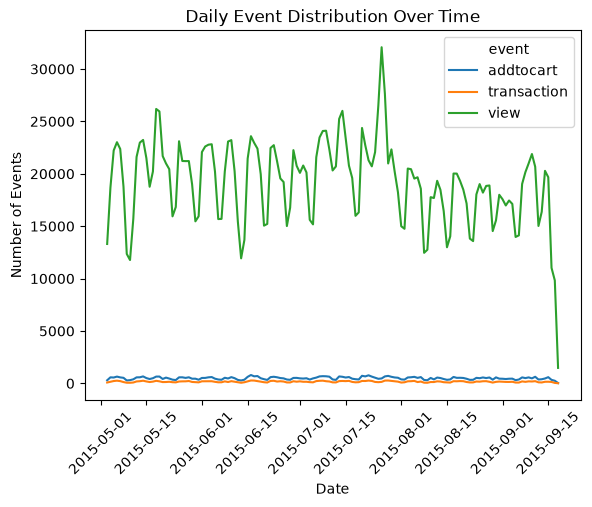

In [40]:
daily_events.plot()

plt.title("Daily Event Distribution Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.show()

In [41]:
df["month"] = df["datetime"].dt.to_period("M")

monthly_events = pd.crosstab(
    df["month"],
    df["event"]
)

print(monthly_events)

event    addtocart  transaction    view
month                                  
2015-05      14318         4611  571655
2015-06      15031         5043  590239
2015-07      17250         5802  674797
2015-08      14725         4632  533880
2015-09       7642         2369  293647


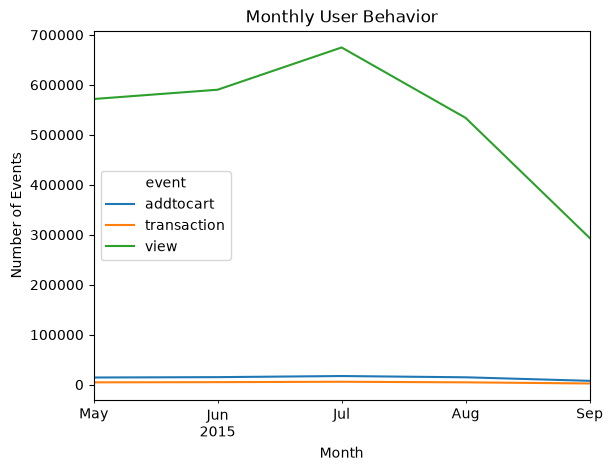

In [42]:
monthly_events.plot()

plt.title("Monthly User Behavior")
plt.xlabel("Month")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.show()

## 4. Key Findings

- Total interactions: 2,756,101
- Unique users: 1,407,580
- Unique products: 235,061
- Event types: view, addtocart, transaction
- View events: 2,664,312
- Add-to-cart events: 69,332
- Transaction events: 22,457
- Unique transactions: 17,672
- Duplicate rows identified: 460
- Duplicate rows removed: 460
- Data period: May 3, 2015 to September 18, 2015

### Data Quality Findings

- timestamp, visitorid, event, and itemid contain no missing values.
- transactionid contains 2,733,644 missing values because non-purchase events do not have a transaction ID.
- transactionid contains missing values because most interactions are views or add-to-cart events.
- No negative visitor IDs were found.
- No negative item IDs were found.
- Three valid event types were identified.
- Exact duplicate records were removed before creating the cleaned dataset.

In [44]:
import os

print("Current notebook folder:")
print(os.getcwd())

Current notebook folder:
c:\Users\Poorvi\OneDrive\Desktop\Recommendation-Drift-Monitoring\notebooks


In [45]:
print("Files/folders here:")
print(os.listdir())

Files/folders here:
['01_dataset_download.ipynb']


In [46]:
import os

print(os.listdir("../data"))

['processed', 'raw']


In [47]:
print(os.listdir("../data/processed"))

[]


In [48]:
print(os.listdir("../data/raw"))

[]


In [49]:
print(os.listdir("../data/processed"))

['events_cleaned.csv']


## 5. Product Analysis
### 5.1 Product Popularity

In [50]:
product_activity = df["itemid"].value_counts()

print("Average interactions per product:", product_activity.mean())
print("Median interactions per product:", product_activity.median())
print("Maximum interactions for one product:", product_activity.max())

Average interactions per product: 11.723088900328
Median interactions per product: 3.0
Maximum interactions for one product: 3412


In [51]:
top_products = product_activity.head(10)

print(top_products)

itemid
187946    3412
461686    2975
5411      2334
370653    1854
219512    1800
257040    1647
298009    1642
96924     1633
309778    1628
384302    1608
Name: count, dtype: int64


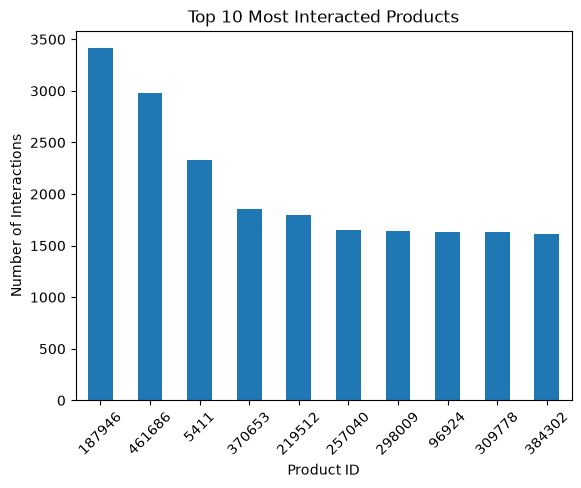

In [52]:
top_products.plot(kind="bar")

plt.title("Top 10 Most Interacted Products")
plt.xlabel("Product ID")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=45)
plt.show()

### 5.2 Daily Interaction Activity

In [53]:
daily_activity = df.groupby(
    df["datetime"].dt.date
).size()

print(daily_activity.head())

datetime
2015-05-03    13682
2015-05-04    19413
2015-05-05    23011
2015-05-06    23920
2015-05-07    23157
dtype: int64


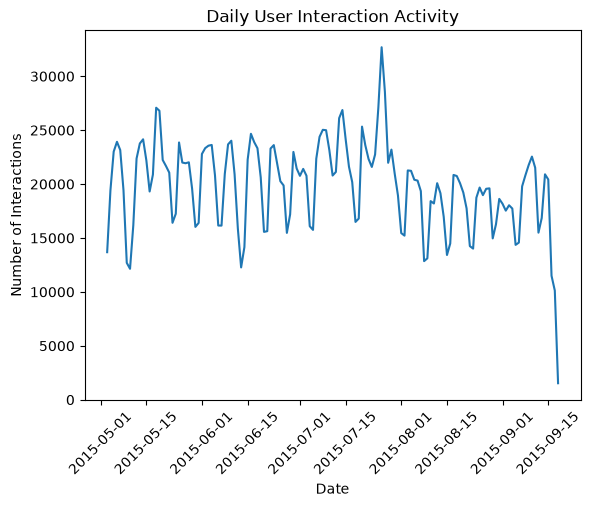

In [54]:
daily_activity.plot()

plt.title("Daily User Interaction Activity")
plt.xlabel("Date")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=45)
plt.show()

### 5.3 Event Behavior Over Time

In [55]:
daily_events = pd.crosstab(
    df["datetime"].dt.date,
    df["event"]
)

print(daily_events.head())

event       addtocart  transaction   view
datetime                                 
2015-05-03        296           83  13303
2015-05-04        578          154  18681
2015-05-05        561          225  22225
2015-05-06        647          258  23015
2015-05-07        572          217  22368


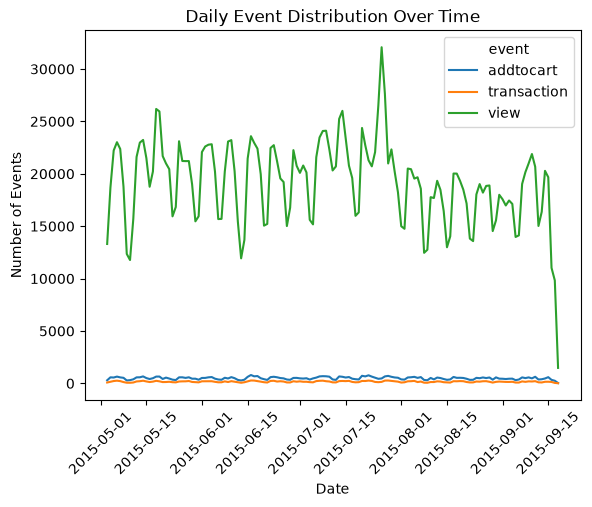

In [56]:
daily_events.plot()

plt.title("Daily Event Distribution Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.show()

### 5.4 Monthly User Behavior

In [57]:
df["month"] = df["datetime"].dt.to_period("M")

monthly_events = pd.crosstab(
    df["month"],
    df["event"]
)

print(monthly_events)

event    addtocart  transaction    view
month                                  
2015-05      14318         4611  571655
2015-06      15031         5043  590239
2015-07      17250         5802  674797
2015-08      14725         4632  533880
2015-09       7642         2369  293647


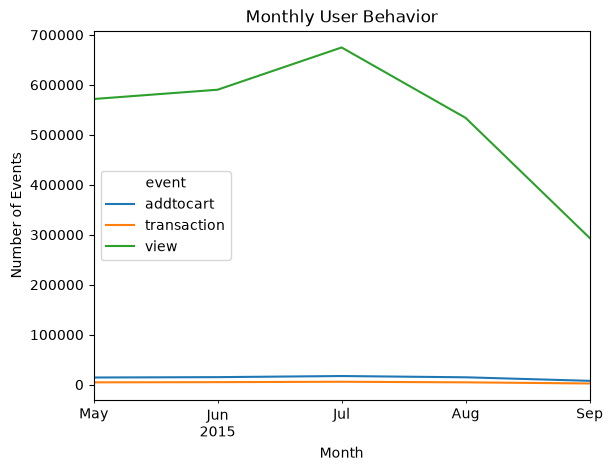

In [58]:
monthly_events.plot()

plt.title("Monthly User Behavior")
plt.xlabel("Month")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.show()

## 6. Time-Based Dataset Preparation
### 6.1 Define Time Periods

In [69]:
print("Minimum date:", df["datetime"].min())
print("Maximum date:", df["datetime"].max())

Minimum date: 2015-05-03 03:00:04.384000
Maximum date: 2015-09-18 02:59:47.788000


In [70]:
def assign_period(date):
    if date.month in [5, 6]:
        return "baseline"
    elif date.month in [7, 8]:
        return "comparison"
    else:
        return "recent"

df["period"] = df["datetime"].apply(assign_period)

In [71]:
print(df["period"].value_counts())

period
comparison    1251086
baseline      1200897
recent         303658
Name: count, dtype: int64


In [72]:
period_events = pd.crosstab(
    df["period"],
    df["event"]
)

print(period_events)

event       addtocart  transaction     view
period                                     
baseline        29349         9654  1161894
comparison      31975        10434  1208677
recent           7642         2369   293647


In [73]:
period_event_percent = period_events.div(
    period_events.sum(axis=1),
    axis=0
) * 100

print(period_event_percent.round(2))

event       addtocart  transaction   view
period                                   
baseline         2.44         0.80  96.75
comparison       2.56         0.83  96.61
recent           2.52         0.78  96.70


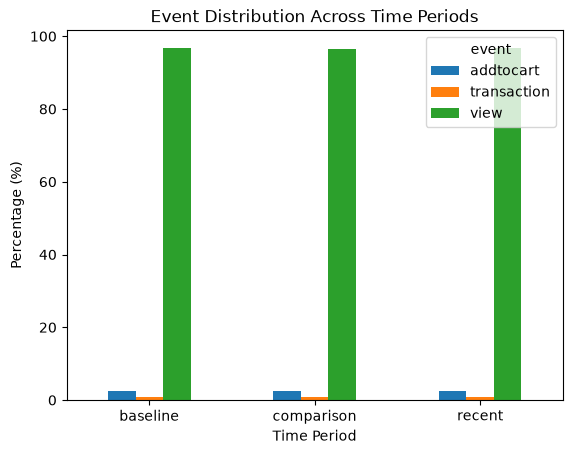

In [74]:
period_event_percent.plot(kind="bar")

plt.title("Event Distribution Across Time Periods")
plt.xlabel("Time Period")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.show()

In [75]:
df.to_csv(
    "../data/processed/events_cleaned.csv",
    index=False
)

print("Updated cleaned dataset saved!")

Updated cleaned dataset saved!


In [76]:
df["period"] = df["datetime"].apply(assign_period)

In [77]:
print(df["period"].value_counts())

period
comparison    1251086
baseline      1200897
recent         303658
Name: count, dtype: int64


In [78]:
print(period_event_percent.round(2))

event       addtocart  transaction   view
period                                   
baseline         2.44         0.80  96.75
comparison       2.56         0.83  96.61
recent           2.52         0.78  96.70


### 6.2 User Activity Across Time Periods

In [79]:
user_period_activity = df.groupby(
    ["period", "visitorid"]
).size()

print(user_period_activity.groupby(level=0).mean())

period
baseline      1.979186
comparison    1.855682
recent        1.747893
dtype: float64


In [80]:
print(user_period_activity.groupby(level=0).median())

period
baseline      1.0
comparison    1.0
recent        1.0
dtype: float64


In [81]:
print(user_period_activity.groupby(level=0).max())

period
baseline      2410
comparison    4828
recent        1200
dtype: int64


In [82]:
unique_users_period = df.groupby("period")["visitorid"].nunique()

print(unique_users_period)

period
baseline      606763
comparison    674192
recent        173728
Name: visitorid, dtype: int64


In [83]:
unique_products_period = df.groupby("period")["itemid"].nunique()

print(unique_products_period)

period
baseline      162894
comparison    168229
recent         82220
Name: itemid, dtype: int64


In [84]:
period_summary = pd.DataFrame({
    "interactions": df.groupby("period").size(),
    "unique_users": df.groupby("period")["visitorid"].nunique(),
    "unique_products": df.groupby("period")["itemid"].nunique()
})

print(period_summary)

            interactions  unique_users  unique_products
period                                                 
baseline         1200897        606763           162894
comparison       1251086        674192           168229
recent            303658        173728            82220


In [85]:
period_summary.to_csv(
    "../data/processed/period_summary.csv"
)

print("Period summary saved!")

Period summary saved!


In [86]:
import scipy
print(scipy.__version__)

1.18.1


In [87]:
## 7. Drift Analysis
### 7.1 Jensen-Shannon Divergence

In [88]:
import numpy as np
from scipy.spatial.distance import jensenshannon

# Convert event counts into probabilities
baseline_dist = (
    period_events.loc["baseline"] /
    period_events.loc["baseline"].sum()
)

comparison_dist = (
    period_events.loc["comparison"] /
    period_events.loc["comparison"].sum()
)

recent_dist = (
    period_events.loc["recent"] /
    period_events.loc["recent"].sum()
)

# Calculate JSD
jsd_baseline_comparison = jensenshannon(
    baseline_dist,
    comparison_dist
)

jsd_baseline_recent = jensenshannon(
    baseline_dist,
    recent_dist
)

print("JSD (Baseline vs Comparison):", jsd_baseline_comparison)
print("JSD (Baseline vs Recent):", jsd_baseline_recent)

JSD (Baseline vs Comparison): 0.00281068962659405
JSD (Baseline vs Recent): 0.001893774250869223


### 7.2 Product Popularity Drift

In [89]:
product_period = pd.crosstab(
    df["itemid"],
    df["period"]
)

print(product_period.head())

period  baseline  comparison  recent
itemid                              
3              0           2       0
4              1           1       1
6             15          14       0
9              1           1       0
15             9          13       0


In [90]:
top_baseline = (
    df[df["period"] == "baseline"]["itemid"]
    .value_counts()
    .head(10)
)

top_comparison = (
    df[df["period"] == "comparison"]["itemid"]
    .value_counts()
    .head(10)
)

top_recent = (
    df[df["period"] == "recent"]["itemid"]
    .value_counts()
    .head(10)
)

print("Top 10 Baseline Products:")
print(top_baseline)

print("\nTop 10 Comparison Products:")
print(top_comparison)

print("\nTop 10 Recent Products:")
print(top_recent)

Top 10 Baseline Products:
itemid
309778    1239
5411      1220
370653    1167
369447    1116
298009    1050
257040     941
7943       848
335975     822
111530     795
96924      784
Name: count, dtype: int64

Top 10 Comparison Products:
itemid
187946    2679
461686    1681
219512    1371
384302    1208
5411       954
190000     866
445351     854
441852     838
441668     800
320130     787
Name: count, dtype: int64

Top 10 Recent Products:
itemid
187946    716
434782    660
461686    579
17114     493
76060     469
320130    380
245085    343
461190    334
190000    299
219512    265
Name: count, dtype: int64


In [91]:
baseline_set = set(top_baseline.index)
comparison_set = set(top_comparison.index)
recent_set = set(top_recent.index)

print(
    "Baseline vs Comparison overlap:",
    len(baseline_set & comparison_set),
    "/ 10"
)

print(
    "Baseline vs Recent overlap:",
    len(baseline_set & recent_set),
    "/ 10"
)

Baseline vs Comparison overlap: 1 / 10
Baseline vs Recent overlap: 0 / 10


In [92]:
product_counts = pd.crosstab(
    df["period"],
    df["itemid"]
)

product_probabilities = product_counts.div(
    product_counts.sum(axis=1),
    axis=0
)

In [93]:
jsd_product_baseline_comparison = jensenshannon(
    product_probabilities.loc["baseline"],
    product_probabilities.loc["comparison"]
)

jsd_product_baseline_recent = jensenshannon(
    product_probabilities.loc["baseline"],
    product_probabilities.loc["recent"]
)

print(
    "Product JSD (Baseline vs Comparison):",
    jsd_product_baseline_comparison
)

print(
    "Product JSD (Baseline vs Recent):",
    jsd_product_baseline_recent
)

Product JSD (Baseline vs Comparison): 0.3927915813427789
Product JSD (Baseline vs Recent): 0.5202878360036652


### 7.3 Product Drift Visualization

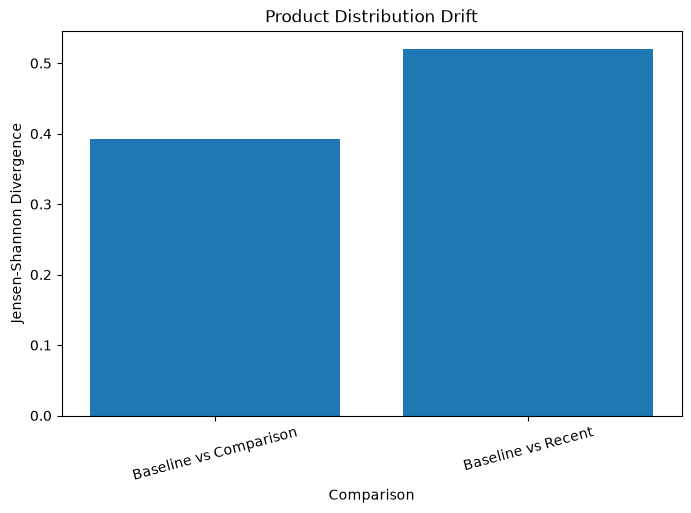

In [94]:
product_jsd_values = [
    jsd_product_baseline_comparison,
    jsd_product_baseline_recent
]

labels = [
    "Baseline vs Comparison",
    "Baseline vs Recent"
]

plt.figure(figsize=(8, 5))
plt.bar(labels, product_jsd_values)

plt.title("Product Distribution Drift")
plt.xlabel("Comparison")
plt.ylabel("Jensen-Shannon Divergence")
plt.xticks(rotation=15)
plt.show()

### 7.4 Drift Results Summary

In [95]:
drift_results = pd.DataFrame({
    "Comparison": [
        "Baseline vs Comparison",
        "Baseline vs Recent"
    ],
    "Event_JSD": [
        jsd_baseline_comparison,
        jsd_baseline_recent
    ],
    "Product_JSD": [
        jsd_product_baseline_comparison,
        jsd_product_baseline_recent
    ]
})

print(drift_results)

               Comparison  Event_JSD  Product_JSD
0  Baseline vs Comparison   0.002811     0.392792
1      Baseline vs Recent   0.001894     0.520288


In [96]:
drift_results.to_csv(
    "../data/processed/drift_results.csv",
    index=False
)

print("Drift results saved successfully!")

Drift results saved successfully!


## 8. Drift Analysis Findings

### Event Distribution

The event-type distribution remained relatively stable across the
three time periods. Jensen-Shannon Divergence between the baseline
and comparison periods was approximately 0.00281, while the
baseline versus recent period was approximately 0.00189.

This indicates little change in the overall proportions of views,
add-to-cart events, and transactions.

### Product Distribution

A substantially larger shift was observed in product-interaction
behavior.

The Product JSD was approximately 0.39279 for baseline versus
comparison and 0.52029 for baseline versus recent.

The Top-10 product overlap was only 1/10 between baseline and
comparison and 0/10 between baseline and recent.

This indicates that the products receiving user interactions
changed considerably over time.

### Preliminary Conclusion

The analysis indicates that product-level behavior experienced
substantial distribution shift, while the overall event-type
distribution remained relatively stable.

This represents evidence of data drift relevant to an
e-commerce recommendation system. However, model degradation
cannot be concluded from these results alone because recommendation
model performance has not yet been evaluated.

### 7.5 User Behavioral Drift

In [97]:
user_period_activity = df.groupby(
    ["period", "visitorid"]
).size()

user_activity_summary = user_period_activity.groupby(
    level=0
).agg(["mean", "median", "max"])

print(user_activity_summary)

                mean  median   max
period                            
baseline    1.979186     1.0  2410
comparison  1.855682     1.0  4828
recent      1.747893     1.0  1200


In [98]:
active_users = df.groupby("period")["visitorid"].nunique()

print(active_users)

period
baseline      606763
comparison    674192
recent        173728
Name: visitorid, dtype: int64


In [99]:
interactions_per_active_user = (
    df.groupby("period").size()
    / df.groupby("period")["visitorid"].nunique()
)

print(interactions_per_active_user)

period
baseline      1.979186
comparison    1.855682
recent        1.747893
dtype: float64


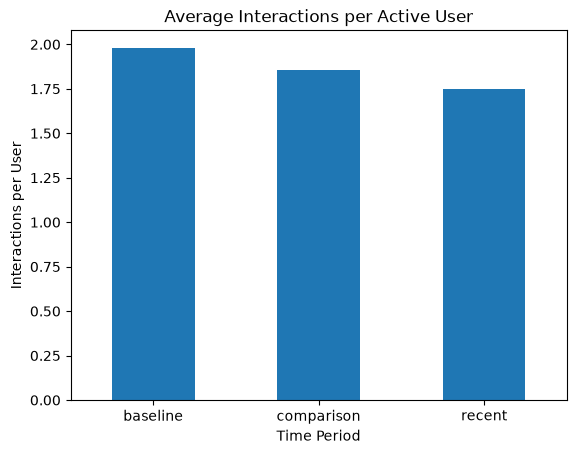

In [100]:
interactions_per_active_user.plot(kind="bar")

plt.title("Average Interactions per Active User")
plt.xlabel("Time Period")
plt.ylabel("Interactions per User")
plt.xticks(rotation=0)
plt.show()

In [101]:
user_counts = pd.crosstab(
    df["period"],
    df["visitorid"]
)

In [102]:
user_probabilities = user_counts.div(
    user_counts.sum(axis=1),
    axis=0
)

In [103]:
jsd_user_baseline_comparison = jensenshannon(
    user_probabilities.loc["baseline"],
    user_probabilities.loc["comparison"]
)

jsd_user_baseline_recent = jensenshannon(
    user_probabilities.loc["baseline"],
    user_probabilities.loc["recent"]
)

print(
    "User JSD (Baseline vs Comparison):",
    jsd_user_baseline_comparison
)

print(
    "User JSD (Baseline vs Recent):",
    jsd_user_baseline_recent
)

User JSD (Baseline vs Comparison): 0.7988271597937261
User JSD (Baseline vs Recent): 0.8193017114038538


In [104]:
drift_results["User_JSD"] = [
    jsd_user_baseline_comparison,
    jsd_user_baseline_recent
]

print(drift_results)

               Comparison  Event_JSD  Product_JSD  User_JSD
0  Baseline vs Comparison   0.002811     0.392792  0.798827
1      Baseline vs Recent   0.001894     0.520288  0.819302


In [106]:
drift_results.to_csv(
    "../data/processed/drift_results.csv",
    index=False
)

print("Updated drift results saved!")

Updated drift results saved!


In [107]:
final_summary = pd.DataFrame({
    "Metric": [
        "Total interactions",
        "Unique users",
        "Unique products",
        "Unique transactions",
        "Duplicate rows removed",
        "Event JSD: Baseline vs Comparison",
        "Event JSD: Baseline vs Recent",
        "Product JSD: Baseline vs Comparison",
        "Product JSD: Baseline vs Recent",
        "User JSD: Baseline vs Comparison",
        "User JSD: Baseline vs Recent",
        "Avg interactions/user: Baseline",
        "Avg interactions/user: Comparison",
        "Avg interactions/user: Recent"
    ],
    "Value": [
        2756101,
        1407580,
        235061,
        17672,
        460,
        jsd_baseline_comparison,
        jsd_baseline_recent,
        jsd_product_baseline_comparison,
        jsd_product_baseline_recent,
        jsd_user_baseline_comparison,
        jsd_user_baseline_recent,
        interactions_per_active_user["baseline"],
        interactions_per_active_user["comparison"],
        interactions_per_active_user["recent"]
    ]
})

print(final_summary)

                                 Metric         Value
0                    Total interactions  2.756101e+06
1                          Unique users  1.407580e+06
2                       Unique products  2.350610e+05
3                   Unique transactions  1.767200e+04
4                Duplicate rows removed  4.600000e+02
5     Event JSD: Baseline vs Comparison  2.810690e-03
6         Event JSD: Baseline vs Recent  1.893774e-03
7   Product JSD: Baseline vs Comparison  3.927916e-01
8       Product JSD: Baseline vs Recent  5.202878e-01
9      User JSD: Baseline vs Comparison  7.988272e-01
10         User JSD: Baseline vs Recent  8.193017e-01
11      Avg interactions/user: Baseline  1.979186e+00
12    Avg interactions/user: Comparison  1.855682e+00
13        Avg interactions/user: Recent  1.747893e+00


In [108]:
final_summary.to_csv(
    "../data/processed/phase1_summary.csv",
    index=False
)

print("Phase 1 summary saved!")

Phase 1 summary saved!


## 9. Phase 1 Conclusion

The Retailrocket e-commerce events dataset was successfully collected,
cleaned, and analyzed.

The dataset contains 2,756,101 user-product interactions involving
1,407,580 users and 235,061 products over the period from May 3, 2015
to September 18, 2015.

Duplicate records were identified and removed during preprocessing.
The cleaned dataset was stored separately from the original raw dataset.

The data was divided into three time periods:

- Baseline: May–June 2015
- Comparison: July–August 2015
- Recent: September 2015

The analysis showed that the overall event distribution remained
relatively stable across the periods. However, product-level and
user-level behavior showed substantially larger distribution shifts.

The average number of interactions per active user decreased from
approximately 1.98 in the baseline period to 1.86 in the comparison
period and 1.75 in the recent period.

These results provide evidence of changes in e-commerce user and
product interaction behavior over time. Such changes may affect a
recommendation system and therefore motivate further monitoring of
data drift and model performance.

However, model degradation cannot be concluded from Phase 1 alone,
because recommendation-model performance has not yet been evaluated.

In [109]:
import os

processed_path = "../data/processed"

os.makedirs(processed_path, exist_ok=True)

print("Processed folder exists:", os.path.exists(processed_path))

Processed folder exists: True


In [110]:
print(os.listdir("../data"))

['processed', 'raw']


In [111]:
print(os.listdir("../data/processed"))

['drift_results.csv', 'events_cleaned.csv', 'period_summary.csv', 'phase1_summary.csv']


In [112]:
import os

files = os.listdir("../data/processed")

print("Files in processed folder:")
for file in files:
    print(file)

Files in processed folder:
drift_results.csv
events_cleaned.csv
period_summary.csv
phase1_summary.csv
